# 05 &nbsp;At what monthly volume does fine-tuning pay off, and when does the answer flip?

**The problem.** Notebooks 02 to 04 measured each option's accuracy, price per request and speed. A team still has to turn those into one decision: keep paying a hosted model per request, or pay once for labels and training and then a fixed amount every month to run a small model themselves. The answer depends on how many requests they serve, what a wrong answer costs them, and how much their own time costs.

**The approach.**

1. Write each option as a monthly bill: a fixed part, a part per request, and a part for wrong answers.
2. Use the measured numbers where the study has them (prices, token use, accuracy) and state every assumption it does not (engineer time, label price).
3. Find the monthly volume where the bills cross, first on price alone and then counting what a wrong answer costs.
4. Map which option is cheapest for every volume and cost of a mistake, then vary each assumption to see which ones can flip the answer.

The self-hosted option is the fine-tuned model trained on all labels. Section 6 asks whether the model that was not fine-tuned would do just as well.

Notebook 02 (section 7) found a fifth option that beats both: Haiku given each message's 10 most similar labelled examples. It is a hybrid. Like self-hosting, it needs all the labels and a small model on a server (the embedding model that finds the similar examples); like prompting, it also pays per request. It is costed here the same way.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb

from fopstudy import style
from fopstudy.costs import (SERVER_PER_HOUR, Option, break_even_volume, cheapest, error_cost_to_break_even,
                            server_monthly_cost)
from fopstudy.evaluate import paired_difference
from fopstudy.results import RESULTS_DIR, correctness

style.use_style()
runs = pd.read_csv(RESULTS_DIR / "runs_api.csv").set_index("run")
rows = correctness("sonnet", 5).index  # the 1,540 messages every option answered
right = {
    "haiku0": correctness("haiku", 0).loc[rows], "haiku5": correctness("haiku", 5).loc[rows],
    "sonnet5": correctness("sonnet", 5).loc[rows],
    "finetuned": correctness("finetuned", "all", seeds=(0, 1, 2)).loc[rows],
    "finetuned50": correctness("finetuned", 50, seeds=(0, 1, 2)).loc[rows],
    "frozen": correctness("frozen", "all").loc[rows], "frozen50": correctness("frozen", 50, seeds=(0, 1, 2)).loc[rows],
    "hybrid": correctness("haiku_retrieved10", "all").loc[rows],
}

## 1. What is measured and what is assumed

Change any assumption below and rerun the notebook; every chart and table follows. The base case is meant to be ordinary, not flattering to either side.

In [2]:
BASE = {
    "server_monthly": server_monthly_cost(),  # measured price, notebook 04
    "hourly_rate": 100.0,          # an engineer's time, dollars an hour
    "selfhost_hours": 4.0,         # a month spent keeping the small model and its server running
    "hosted_hours": 1.0,           # a month spent watching the prompt and model updates
    "label_price": 0.50,           # dollars to label one message
    "label_months": 12,            # months the one-off labelling is spread over
    "selfhost_labels": 10_003,     # every training message: 9,000 to train, 1,003 to tune
    "prompt_labels": 385,          # 5 examples per intent in the prompt
    "retrain_monthly": 2.0,        # a 15-minute training run on a rented GPU each month
    "hosted_price_factor": 1.0,    # 0.5 for the Batch API
}
pd.DataFrame([
    ("Hosted price per 1,000 requests", "Measured", "From every request's tokens (notebook 04)"),
    ("Accuracy", "Measured", "On the same 1,540 test messages (notebook 02)"),
    ("Server", "Measured price", f"AWS c7g.large on demand, ${BASE['server_monthly']:.2f} a month"),
    ("Engineer time", "Assumed", f"${BASE['hourly_rate']:.0f} an hour; {BASE['selfhost_hours']:.0f} hours a month self-hosted, "
                                 f"{BASE['hosted_hours']:.0f} hosted"),
    ("Labels", "Assumed", f"${BASE['label_price']:.2f} each, paid off over {BASE['label_months']} months"),
    ("Retraining", "Assumed", f"${BASE['retrain_monthly']:.0f} a month of rented GPU time"),
    ("Hybrid", "Assumed", "Runs the embedding model on the same kind of server, so the same engineer time and labels as "
                          "self-hosting, plus the measured hosted price; no training"),
], columns=["Input", "Source", "Base case"]).style.hide(axis="index")

Input,Source,Base case
"Hosted price per 1,000 requests",Measured,From every request's tokens (notebook 04)
Accuracy,Measured,"On the same 1,540 test messages (notebook 02)"
Server,Measured price,"AWS c7g.large on demand, $52.92 a month"
Engineer time,Assumed,"$100 an hour; 4 hours a month self-hosted, 1 hosted"
Labels,Assumed,"$0.50 each, paid off over 12 months"
Retraining,Assumed,$2 a month of rented GPU time
Hybrid,Assumed,"Runs the embedding model on the same kind of server, so the same engineer time and labels as self-hosting, plus the measured hosted price; no training"


In [3]:
def options(a=BASE, selfhost="finetuned"):
    labels = lambda n: n * a["label_price"] / a["label_months"]
    hosted_fixed = a["hosted_hours"] * a["hourly_rate"]
    price = lambda run: runs.loc[run, "cost_per_1k"] * a["hosted_price_factor"]
    selfhost_labels = 50 * 77 if selfhost.endswith("50") else a["selfhost_labels"]
    return [
        Option("Haiku, no examples", price("haiku_shots0"), hosted_fixed, 1 - right["haiku0"].mean()),
        Option("Haiku, 5 examples", price("haiku_shots5"), hosted_fixed + labels(a["prompt_labels"]),
               1 - right["haiku5"].mean()),
        Option("Sonnet, 5 examples", price("sonnet_shots5"), hosted_fixed + labels(a["prompt_labels"]),
               1 - right["sonnet5"].mean()),
        Option("Self-hosted, fine-tuned", 0.0,
               a["server_monthly"] + a["selfhost_hours"] * a["hourly_rate"] + labels(selfhost_labels)
               + (a["retrain_monthly"] if selfhost.startswith("finetuned") else 0.0),
               1 - right[selfhost].mean()),
        Option("Hybrid: Haiku, retrieved examples", price("haiku_retrieved10"),
               a["server_monthly"] + a["selfhost_hours"] * a["hourly_rate"] + labels(a["selfhost_labels"]),
               1 - right["hybrid"].mean()),
    ]

def break_even(hosted, selfhosted, cost_per_error=0.0):
    return break_even_volume(hosted.per_1k, max(selfhosted.fixed_monthly - hosted.fixed_monthly, 0.0),
                             selfhosted.per_1k, hosted.error_rate, selfhosted.error_rate, cost_per_error)

base = options()
COLOURS = [style.APPROACH_COLORS["haiku"], style.APPROACH_COLORS["haiku"], style.APPROACH_COLORS["sonnet"],
           style.APPROACH_COLORS["finetuned"], "#C96C8E"]  # the hybrid gets a colour of its own
pd.DataFrame({"Per 1,000 requests ($)": [o.per_1k for o in base], "Fixed a month ($)": [o.fixed_monthly for o in base],
              "Wrong answers": [o.error_rate for o in base]}, index=[o.name for o in base]).style.format(
    {"Per 1,000 requests ($)": "{:.3f}", "Fixed a month ($)": "{:,.0f}", "Wrong answers": "{:.1%}"})

,"Per 1,000 requests ($)",Fixed a month ($),Wrong answers
"Haiku, no examples",0.031,100,21.0%
"Haiku, 5 examples",0.113,116,13.3%
"Sonnet, 5 examples",1.274,116,10.1%
"Self-hosted, fine-tuned",0.000,872,6.7%
"Hybrid: Haiku, retrieved examples",0.061,870,5.7%


The self-hosted model's fixed cost is mostly people and labels, not the server: the server is about \$53 of it. That is why the break-even volumes below are higher than a comparison of server price against API price would suggest.

## 2. On price alone

,"Break-even requests a month, price only"
"Haiku, no examples","24,838,800"
"Haiku, 5 examples","6,679,410"
"Sonnet, 5 examples","593,293"


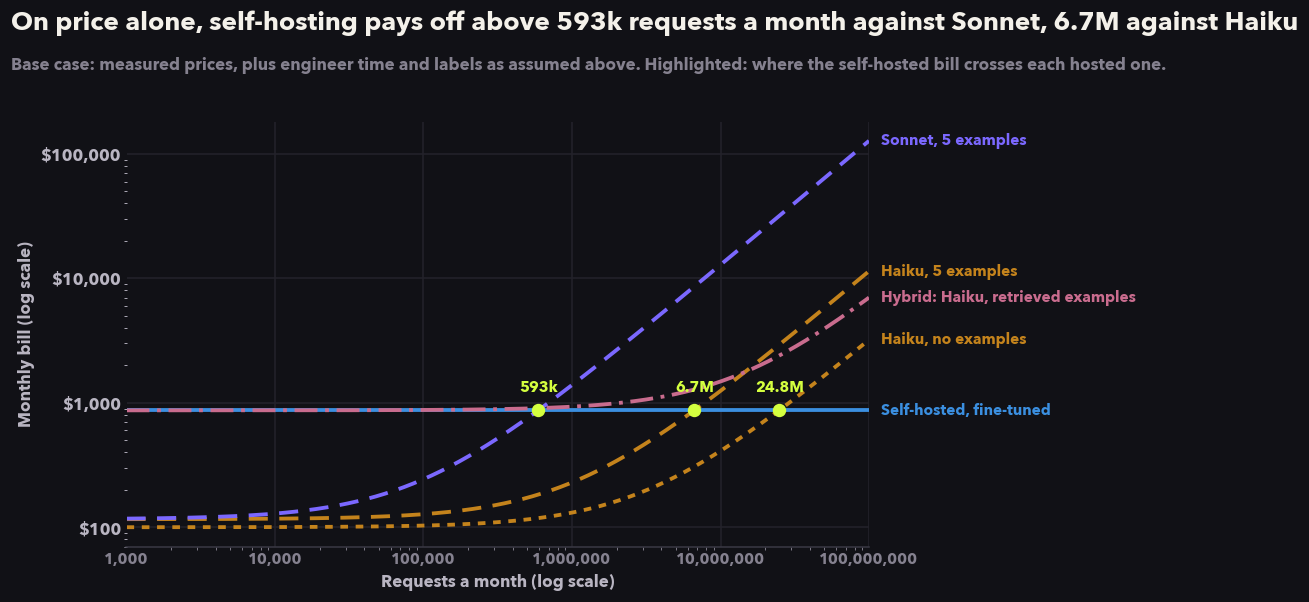

In [4]:
volume = np.logspace(3, 8, 400)
fig, ax = plt.subplots(figsize=(10, 5.6))
for o, colour, dash in zip(base, COLOURS, [(0, (2, 2)), (0, (5, 3)), (0, (5, 3)), "-", (0, (6, 2, 1, 2))]):
    ax.plot(volume, o.monthly(volume), color=colour, linewidth=2.5, linestyle=dash)
    end = o.monthly(volume[-1])
    ax.annotate(f"{o.name}", (volume[-1], end), xytext=(8, 0), textcoords="offset points", va="center",
                color=colour, fontsize=10, fontweight="bold")
crossings = {}
for o in base[:3]:
    v = break_even(o, base[3])
    crossings[o.name] = v
    if np.isfinite(v) and v <= volume[-1]:
        ax.scatter(v, base[3].monthly(v), color=style.HIGHLIGHT, s=60, zorder=4)
        ax.annotate(f"{v / 1e6:.1f}M" if v >= 1e6 else f"{v / 1e3:.0f}k", (v, base[3].monthly(v)), xytext=(0, 12),
                    textcoords="offset points", ha="center", color=style.HIGHLIGHT, fontsize=10, fontweight="bold")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e3, 1e8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Requests a month (log scale)")
ax.set_ylabel("Monthly bill (log scale)")
ax.grid(axis="y")
fig.subplots_adjust(top=0.80, right=0.80)
style.headline(fig, f"On price alone, self-hosting pays off above {crossings['Sonnet, 5 examples'] / 1e3:,.0f}k requests a month "
                    f"against Sonnet, {crossings['Haiku, 5 examples'] / 1e6:.1f}M against Haiku",
               "Base case: measured prices, plus engineer time and labels as assumed above. "
               "Highlighted: where the self-hosted bill crosses each hosted one.")
style.save(fig, "monthly_bills")
pd.Series({k: f"{v:,.0f}" for k, v in crossings.items()}, name="Break-even requests a month, price only").to_frame()

Haiku is cheap enough that, on price alone, a small self-hosted model only pays off at several million requests a month. Against Sonnet, a few hundred thousand is enough.

## 3. Counting what a wrong answer costs

A wrong intent sends a customer to the wrong queue, triggers the wrong automatic reply, or makes an agent re-route the message. What that costs depends entirely on the business: a fraction of a cent if an agent fixes it in seconds, dollars if a customer gives up. The self-hosted model makes fewer mistakes than every prompt with fixed examples, so each mistake it avoids counts towards its fixed cost.

Accuracy gaps are measured, so they come with intervals. The ranges below are the break-even volumes at the two ends of the 95% interval for the accuracy gap.

In [5]:
def gap(key):
    return paired_difference(right["finetuned"], right[key])

table = []
for o, key in zip(base[:3], ["haiku0", "haiku5", "sonnet5"]):
    g, lo, hi = gap(key)
    for c in [0.0, 0.001, 0.01, 0.1, 1.0]:
        mid = break_even(o, base[3], c)
        fast = break_even(Option(o.name, o.per_1k, o.fixed_monthly, base[3].error_rate + hi), base[3], c)
        slow = break_even(Option(o.name, o.per_1k, o.fixed_monthly, base[3].error_rate + lo), base[3], c)
        table.append({"Against": o.name, "Cost of one wrong answer": f"${c:g}", "Break-even": mid,
                      "Range": f"{fast:,.0f} to {slow:,.0f}" if c else "(price only)"})
table = pd.DataFrame(table).set_index(["Against", "Cost of one wrong answer"])
table.style.format({"Break-even": "{:,.0f}"})

In [6]:
at = [100_000, 1_000_000]
pd.DataFrame({f"{v:,} requests a month": [error_cost_to_break_even(v, o.per_1k, max(base[3].fixed_monthly - o.fixed_monthly, 0),
                                                                   o.error_rate, base[3].error_rate)
                                          for o in base[:3]] for v in at},
             index=[f"against {o.name}" for o in base[:3]]).style.format("${:.3f}")

,"100,000 requests a month","1,000,000 requests a month"
"against Haiku, no examples",$0.054,$0.005
"against Haiku, 5 examples",$0.113,$0.010
"against Sonnet, 5 examples",$0.185,$0.000


The second table turns the question around: at a given volume, how much must a wrong answer cost before self-hosting pays? At a million requests a month the answer is about a cent or less against every prompt. If a mistake costs a support agent even a few seconds, the more accurate self-hosted model pays for itself.

### If any defensible answer counts as right

Notebook 02 (section 6) read every message where the fine-tuned model and Sonnet with five examples disagree. Most of the fine-tuned model's lead over Sonnet turned out to be agreement with Banking77's labelling habits: counting answers that are as defensible as the label, Sonnet makes slightly fewer mistakes. If a team would accept any sensible intent, the error counts flip, and so does the case for self-hosting against Sonnet when mistakes are costly.

In [7]:
dis = pd.read_csv(RESULTS_DIR / "hand_check_disagreements.csv").set_index("row")
acceptable = dis["verdict"] != "label only"
def lenient_error(name, strict):
    ok = strict.astype(float).copy()
    other = dis.index[dis["other_answer"] == name]
    ok.loc[other] = acceptable.loc[other].astype(float)
    return 1 - ok.mean()
ft_first = correctness("finetuned", "all").loc[rows]   # the run whose disagreements were read
errors = {"Strict (must match the label)": (1 - right["sonnet5"].mean(), 1 - ft_first.mean()),
          "Lenient (defensible answers count)": (lenient_error("sonnet", right["sonnet5"]),
                                                 lenient_error("finetuned", ft_first))}
sonnet = base[2]
pd.DataFrame({scoring: {f"${c:g} per wrong answer": break_even(Option(sonnet.name, sonnet.per_1k, sonnet.fixed_monthly, e_s),
                                                             Option("self", 0.0, base[3].fixed_monthly, e_f), c)
                        for c in [0.0, 0.01, 0.1, 1.0]}
              for scoring, (e_s, e_f) in errors.items()}).rename_axis("Break-even against Sonnet, 5 examples").style.format(
    lambda v: "never" if np.isinf(v) else f"{v:,.0f}")

,Strict (must match the label),Lenient (defensible answers count)
"Break-even against Sonnet, 5 examples",,
$0 per wrong answer,"593,293","593,293"
$0.01 per wrong answer,"480,588","638,894"
$0.1 per wrong answer,"177,359","2,072,585"
$1 per wrong answer,"24,264",never


Under lenient scoring, a costly mistake no longer helps the self-hosted model against Sonnet; it helps Sonnet. Self-hosting still wins on price at high volume, but the higher the cost of a mistake, the later it pays, and at a dollar a mistake it never does. Haiku's disagreements were not read, so its rows above use strict scoring only.

### Self-hosted against the hybrid

The hybrid has about the same fixed cost as self-hosting (the same server, labels and engineer time, minus the training runs) and adds Haiku's price on every request. So on price alone it never beats self-hosting. But it makes fewer mistakes, so it wins once a mistake costs more than the extra price per request divided by the mistakes it saves. The table gives that cost at three volumes.

In [8]:
selfhosted, hybrid = base[3], base[4]
fewer = selfhosted.error_rate - hybrid.error_rate
pd.DataFrame({f"{v:,} requests a month": [(hybrid.per_1k / 1000 - (selfhosted.fixed_monthly - hybrid.fixed_monthly) / v) / fewer]
              for v in [100_000, 1_000_000, 10_000_000]},
             index=[f"Hybrid wins when a mistake costs more than ({fewer:.1%} fewer mistakes)"]).style.format("${:.4f}")

,"100,000 requests a month","1,000,000 requests a month","10,000,000 requests a month"
Hybrid wins when a mistake costs more than (1.0% fewer mistakes),$0.0041,$0.0058,$0.0060


Above about half a cent per mistake, the hybrid is the cheaper of the two at any volume. Its lead in accuracy is about one point (notebook 02, section 7), with an interval that only just clears zero, so this threshold is uncertain by a factor of several either way.

## 4. A map of the decision

Every combination of monthly volume and cost per wrong answer, coloured by the option with the lowest total bill under the base-case assumptions.

Wrong answer costs $0.001: Haiku, no examples to Self-hosted, fine-tuned at 4,561,922
Wrong answer costs $0.01: Haiku, no examples to Haiku, 5 examples at 23,903; Haiku, 5 examples to Hybrid: Haiku, retrieved examples at 933,093
Wrong answer costs $0.1: Haiku, no examples to Sonnet, 5 examples at 1,681; Sonnet, 5 examples to Hybrid: Haiku, retrieved examples at 134,998


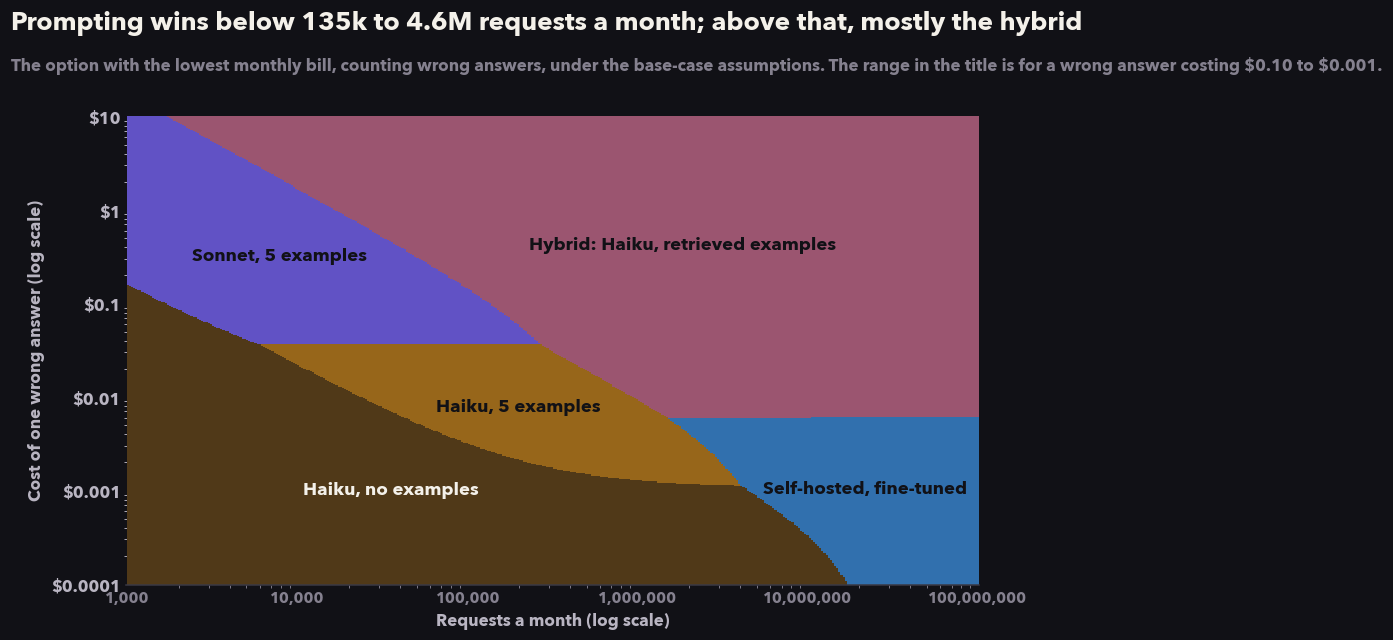

In [9]:
def blend(colour, weight):
    return tuple(weight * np.array(to_rgb(colour)) + (1 - weight) * np.array(to_rgb(style.SURFACE)))

vol = np.logspace(3, 8, 400)
err = np.logspace(-4, 1, 400)
pick = cheapest(base, vol[None, :], err[:, None])
shades = [blend(c, 0.35 if i == 0 else 0.75) for i, c in enumerate(COLOURS)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.pcolormesh(vol, err, pick, cmap=ListedColormap(shades), vmin=-0.5, vmax=len(base) - 0.5, shading="auto", rasterized=True)
for i, o in enumerate(base):
    if (pick == i).any():
        yy, xx = np.nonzero(pick == i)
        ax.text(np.exp(np.log(vol[xx]).mean()), np.exp(np.log(err[yy]).mean()), o.name, ha="center", va="center",
                color=style.SURFACE if i else style.INK, fontsize=12, fontweight="bold")
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_xlabel("Requests a month (log scale)")
ax.set_ylabel("Cost of one wrong answer (log scale)")
ax.grid(False)
fig.subplots_adjust(top=0.82)
switch = lambda c: vol[np.argmax(cheapest(base, vol, c) >= 3)]  # first volume where a model on your own server wins
style.headline(fig, f"Prompting wins below {switch(0.1) / 1e3:.0f}k to {switch(0.001) / 1e6:.1f}M requests a month; "
                    f"above that, mostly the hybrid",
               "The option with the lowest monthly bill, counting wrong answers, under the base-case assumptions. "
               "The range in the title is for a wrong answer costing $0.10 to $0.001.")
style.save(fig, "decision_map")
for c in [0.001, 0.01, 0.1]:
    row = cheapest(base, vol, c)
    flips = [f"{base[a].name} to {base[b].name} at {vol[k + 1]:,.0f}" for k, (a, b) in enumerate(zip(row[:-1], row[1:])) if a != b]
    print(f"Wrong answer costs ${c:g}: " + ("; ".join(flips) if flips else f"{base[row[0]].name} everywhere"))

## 5. Which assumptions can flip the answer?

Each bar changes one assumption from the base case and shows the new break-even volume against Haiku with five examples, on price alone. The longest bars are the assumptions worth pinning down first.

,low_label,low,high_label,high
assumption,,,,
Server,3-year savings plan,"6,438,087",two servers,"7,147,214"
Labels bought,50 per intent,"4,413,312",all (base),"6,679,410"
Engineer's hourly cost,$50,"5,353,560",$200,"9,331,109"
Labels paid off over,36 months,"4,317,924",6 months,"10,221,638"
Hosted price,50% higher,"4,452,940","Batch API, half price","13,358,819"
"Engineer time, self-hosted",1 hour a month,"4,027,710",16 hours a month,"17,286,207"
Price per label,$0.10,"3,845,627",$2.00,"17,306,094"
Cost of one wrong answer,$0.01,"979,941",$0 (base),"6,679,410"


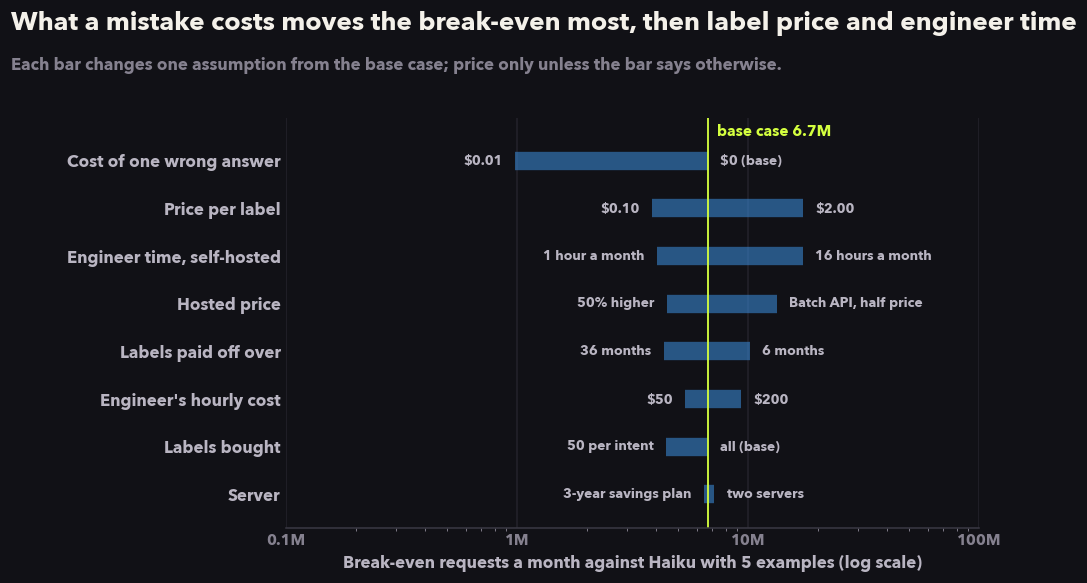

In [10]:
reference = base[1]  # Haiku, 5 examples
def be(**change):
    a = {**BASE, **{k: v for k, v in change.items() if k in BASE}}
    opts = options(a, change.get("selfhost", "finetuned"))
    return break_even(opts[1], opts[3], change.get("cost_per_error", 0.0))

base_be = be()
cases = [
    ("Engineer time, self-hosted", dict(selfhost_hours=1), "1 hour a month", dict(selfhost_hours=16), "16 hours a month"),
    ("Engineer's hourly cost", dict(hourly_rate=50), "$50", dict(hourly_rate=200), "$200"),
    ("Price per label", dict(label_price=0.10), "$0.10", dict(label_price=2.0), "$2.00"),
    ("Labels paid off over", dict(label_months=36), "36 months", dict(label_months=6), "6 months"),
    ("Labels bought", dict(selfhost="finetuned50"), "50 per intent", {}, "all (base)"),
    ("Server", dict(server_monthly=server_monthly_cost(0.0351)), "3-year savings plan",
     dict(server_monthly=2 * server_monthly_cost()), "two servers"),
    ("Hosted price", dict(hosted_price_factor=1.5), "50% higher", dict(hosted_price_factor=0.5), "Batch API, half price"),
    ("Cost of one wrong answer", dict(cost_per_error=0.01), "$0.01", {}, "$0 (base)"),
]
tornado = pd.DataFrame([{"assumption": name, "low": be(**lo), "low_label": lo_label, "high": be(**hi), "high_label": hi_label}
                        for name, lo, lo_label, hi, hi_label in cases])
tornado["span"] = np.log(tornado["high"]) - np.log(tornado["low"])
tornado = tornado.sort_values("span").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5.4))
for i, r in tornado.iterrows():
    ax.plot([r["low"], r["high"]], [i, i], color=style.APPROACH_COLORS["finetuned"], linewidth=12, alpha=0.55,
            solid_capstyle="butt")
    ax.annotate(r["low_label"], (r["low"], i), xytext=(-8, 0), textcoords="offset points", ha="right", va="center",
                color=style.INK_2, fontsize=9)
    ax.annotate(r["high_label"], (r["high"], i), xytext=(8, 0), textcoords="offset points", ha="left", va="center",
                color=style.INK_2, fontsize=9)
ax.axvline(base_be, color=style.HIGHLIGHT, linewidth=1.2)
ax.annotate(f"base case {base_be / 1e6:.1f}M", (base_be, len(tornado) - 0.4), xytext=(6, 0), textcoords="offset points",
            color=style.HIGHLIGHT, fontsize=10, va="center")
ax.set_xscale("log")
ax.set_xlim(1e5, 1e8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:g}M"))
ax.set_yticks(range(len(tornado)))
ax.set_yticklabels(tornado["assumption"])
ax.set_ylim(-0.7, len(tornado) - 0.1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Break-even requests a month against Haiku with 5 examples (log scale)")
fig.subplots_adjust(top=0.80, left=0.27)
style.headline(fig, "What a mistake costs moves the break-even most, then label price and engineer time",
               "Each bar changes one assumption from the base case; price only unless the bar says otherwise.")
style.save(fig, "break_even_sensitivity")
tornado[["assumption", "low_label", "low", "high_label", "high"]].set_index("assumption").style.format(
    {"low": "{:,.0f}", "high": "{:,.0f}"})

## 6. Fine-tuned, or not fine-tuned?

Both small models run on the same server, and both need labels. The differences: the model that was not fine-tuned trains in seconds on a CPU, while fine-tuning needs a GPU; and the fine-tuned model got about one point more right with all labels (a gap that is at the edge of what the test set can detect, notebook 02). Labelling only 50 examples per intent cuts the label bill by more than half, at a cost of about two points.

The table gives each self-hosted variant's monthly bill at a million requests a month, for a few costs per wrong answer.

In [11]:
variants = {"Fine-tuned, all labels": "finetuned", "Not fine-tuned, all labels": "frozen",
            "Fine-tuned, 50 per intent": "finetuned50", "Not fine-tuned, 50 per intent": "frozen50"}
v = 1_000_000
pd.DataFrame({f"${c:g} per wrong answer": {name: options(BASE, key)[3].monthly(v, c) for name, key in variants.items()}
              for c in [0.0, 0.01, 0.1]} | {"Wrong answers": {name: options(BASE, key)[3].error_rate for name, key in variants.items()}}
             ).style.format({"Wrong answers": "{:.1%}"} | {f"${c:g} per wrong answer": "${:,.0f}" for c in [0.0, 0.01, 0.1]})

,$0 per wrong answer,$0.01 per wrong answer,$0.1 per wrong answer,Wrong answers
"Fine-tuned, all labels",$872,"$1,545","$7,603",6.7%
"Not fine-tuned, all labels",$870,"$1,649","$8,662",7.8%
"Fine-tuned, 50 per intent",$615,"$1,490","$9,360",8.7%
"Not fine-tuned, 50 per intent",$613,"$1,466","$9,141",8.5%


When mistakes cost a cent or less, the cheapest self-hosted model is the one with the fewest labels, and it hardly matters whether it is fine-tuned. Once a mistake costs ten cents, the extra accuracy from all labels is worth the labelling, and fine-tuning adds a little more, if its one-point gain holds up. On this task the choice between fine-tuning and not fine-tuning is far less important than the choice between self-hosting and prompting.

## What this means

- **Volume and the cost of a mistake decide; the server price barely matters.** The self-hosted bill is mostly engineer time and labels. The server is about \$53 of a fixed cost near \$870 a month in the base case.
- **On price alone, prompting wins up to millions of requests.** Haiku with five fixed examples stays cheaper than a model of your own until about 7 million requests a month; Sonnet until about 600,000.
- **Counting mistakes moves the line a long way.** If a wrong answer costs a cent, running a model on your own server pays off from about a million requests a month; at ten cents, from about 135,000.
- **At that scale, the hybrid beats plain self-hosting.** Letting the small model find similar labelled examples and Haiku choose the intent costs about 6 cents per 1,000 requests more, and gets about one more answer in a hundred right. That pays once a mistake costs more than about half a cent.
- **What counts as a mistake matters.** If any defensible answer counts as right, Sonnet with fixed examples makes slightly fewer mistakes than the fine-tuned model, and costly mistakes then favour Sonnet over self-hosting.
- **Pin down two numbers first:** what a wrong answer costs, and how many hours a month a model of your own will really take.

**What the data can't tell us.** The engineer time, label price and cost of a mistake are assumptions, which is why section 5 varies them. Costs that are hard to price are left out: the hosted option needs no GPU, no model updates and no on-call; the self-hosted one keeps customer messages in-house and does not change when a provider retires a model. And every number comes from one task, one month's prices and one set of test messages.